Завдання 1: Завантажте дані medical-charges.csv в пандас датафрейм і виведіть перші 5 записів. Напишіть, як ви можете підійти до вирішення задачі прогнозування колонки charges на основі інших колонок виходячи з наявних на даний момент знань (без ML методів, чисто з використанням аналітики). Запишіть 3 або більше ідей, які приходять вам на думку нижче:

In [6]:
import pandas as pd
medical_df = pd.read_csv('medical-charges.csv')
medical_df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


1. Порівняти середні значення витрат у групах курців та некурців.
2. Витрати  в залежності від віку
3. витрати залежності від регіону

Завдання 2: Візуалізуйте розподіл медичних зборів (charges) у вигляді інтерактивної гістограми plotly з розбиттями за категоріями ознак

sex
region
Додайте маржинальний графік у вигляді бокс-плота вгорі по дикретним категоріям ознак. Скористайтесь прикладом візуалізації з лекції. Опишіть свої спостереження.

In [4]:
import plotly.express as px

fig = px.histogram(
    medical_df,
    x='charges',
    color='sex',
    marginal='box',
    nbins=100,
    title='Розподіл медичних зборів за статтю'
)
fig.update_layout(bargap=0.1)
fig.show()

In [5]:
fig = px.histogram(
    medical_df,
    x='charges',
    color='region',
    marginal='box',
    nbins=100,
    title='Розподіл медичних зборів за регіоном'
)
fig.update_layout(bargap=0.1)
fig.show()

Завдання 3: Візуалізуйте з plotly розподіл кожного з настуних стовпців відносно того, чи є людина курцем (smoker)

region
children
та опишіть коротко свої спостереження.

In [10]:
#region відносно smoker
fig = px.histogram(
    medical_df,
    x='region',
    color='smoker',
    barmode='group',
    title='Розподіл регіонів за статусом курця'
)
fig.show()

In [11]:
#children відносно smoker
fig = px.histogram(
    medical_df,
    x='children',
    color='smoker',
    barmode='group',
    title='Розподіл кількості дітей за статусом курця'
)
fig.update_xaxes(type='category')
fig.show()

Завдання 4: Візуалізуйте звʼязок між стовпцем charges та children використовуючи графіки-скрипки (px.violin). Опишіть свої спостереження.

In [13]:
import plotly.express as px

fig = px.violin(
    medical_df,
    x='children',
    y='charges',
    box=True,
    title='Звязок між кількістю дітей та медичними зборами'
)
fig.update_xaxes(type='category')
fig.show()

1) Основна частина значень зосередженна в діапазоні 10-15к.
2) суттєвих змін в витратах з збільшенням дітей не видно.


Розглянемо модель для користувачів, які не є курцями (no_smoker_df):

charges=w×age+b 

Спробуйте 3 різні пари параметрів w та b аби вручну підігнати лінію під дані використовуючи наведені допоміжні функції estimate_charges та try_parameters. Опишіть спостереження. Пари параметрів мають бути НЕ такі, як були наведені в лекції.

In [15]:
import matplotlib.pyplot as plt

non_smoker_df = medical_df[medical_df.smoker == 'no']

def estimate_charges(age, w, b):
    return w * age + b

def try_parameters(df, w, b):
    ages = df.age
    target = df.charges

    estimated_charges = estimate_charges(ages, w, b)

    plt.plot(ages, estimated_charges, 'r', alpha=0.9);
    plt.scatter(ages, target, s=8, alpha=0.8);
    plt.xlabel('Age');
    plt.ylabel('Charges')
    plt.legend(['Estimate', 'Actual']);

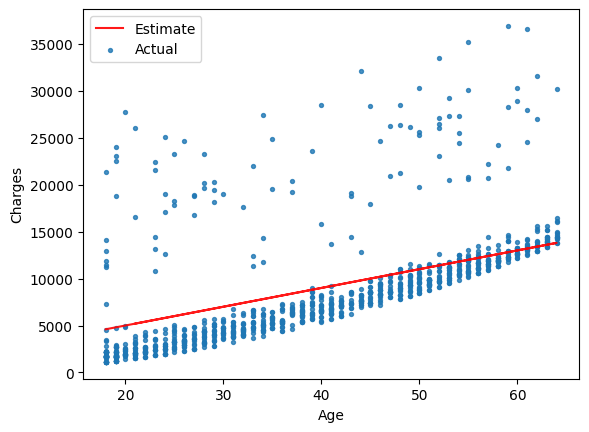

In [16]:
try_parameters(non_smoker_df, 200, 1000)

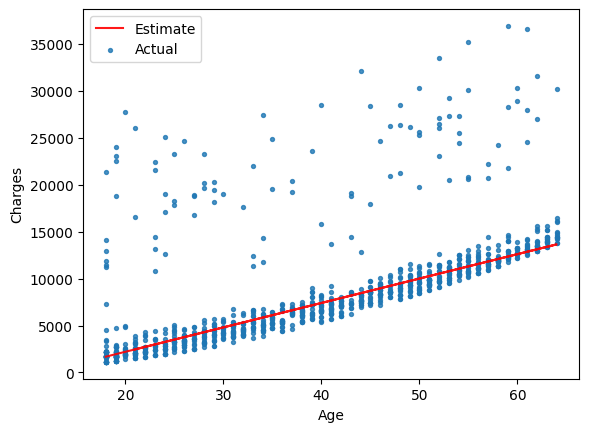

In [17]:
try_parameters(non_smoker_df, 260, -3000)

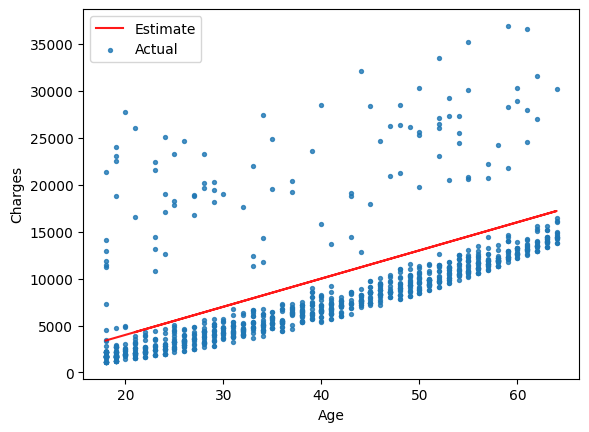

In [18]:
try_parameters(non_smoker_df, 300, -2000)

При w=200, b=1000 лінія надто полога: завищує витрати для молодих і занижує для старших. 
При w=260, b=-3000 лінія найкраще проходить по основній смузі точок. 
При w=300, b=-2000 лінія надто крута й проходить вище за основну масу даних. Частина точок лежить значно вище за лінію в усіх варіантах, тож одного віку недостатньо для точного прогнозу.

Завдання 6: Напишіть фукнцію для обчислення root mean squared error згідно з формулою цієї метрики точності моделі з використанням numpy.

Обчисліть RMSE для тих пар пареметрів, які Ви спробували в завданні 5.

Яке найнижче значення втрат ви зможете досягти? Чи можете ви придумати загальну стратегію для знаходження кращих значень  w  та  b  методом проб та помилок?

In [ ]:
#ФУНКЦІЯ RMSE
import numpy as np

def rmse(targets, predictions):
    return np.sqrt(np.mean(np.square(targets - predictions)))

In [22]:
#RMSE
def try_parameters_rmse(df, w, b):
    predictions = estimate_charges(df.age, w, b)
    return rmse(df.charges, predictions)

for w, b in [(200, 1000), (260, -3000), (300, -2000)]:
    print(f'w={w}, b={b}: RMSE = {try_parameters_rmse(non_smoker_df, w, b):.2f}')

w=200, b=1000: RMSE = 4778.20
w=260, b=-3000: RMSE = 4814.06
w=300, b=-2000: RMSE = 4884.63


Найменше значення у пари (w=200, b=1000), хоча візуально пара (260, -3000) краще описує нижню смугу точок: RMSE враховує і верхні розсіяні точки, які лінія за віком не пояснює.